In [1]:
from fastpynuts import NUTSfinder
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Rectangle
from mpl_toolkits.basemap import Basemap
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import seaborn as sns
import xarray as xr
import pickle 
import cdsapi
from pathlib import Path
import zipfile
import os
import numpy as np

In [2]:
# load demonstrator data preprocessed in map_demonstrator_regions.ipynb
with open('./data/regions/demo_regions.pkl', 'rb') as f:
    demo_regions = pickle.load(f) 

In [3]:
era5d_zipfile = f"./data/era5_drought/era5_drought_greece.zip"

dataset = "derived-drought-historical-monthly"
request = {
    "variable": ["standardised_precipitation_index", "standardised_precipitation_evapotranspiration_index"],
    "accumulation_period": ["6"],
    "version": "1_0",
    "product_type": ["reanalysis"],
    "dataset_type": "consolidated_dataset",
    "year": [
        "1940", "1941", "1942",
        "1943", "1944", "1945",
        "1946", "1947", "1948",
        "1949", "1950", "1951",
        "1952", "1953", "1954",
        "1955", "1956", "1957",
        "1958", "1959", "1960",
        "1961", "1962", "1963",
        "1964", "1965", "1966",
        "1967", "1968", "1969",
        "1970", "1971", "1972",
        "1973", "1974", "1975",
        "1976", "1977", "1978",
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024", "2025"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "area": [45, 15, 30, 30] # Greece extent
}

client = cdsapi.Client()
client.retrieve(dataset, request).download(era5d_zipfile)

2025-11-24 10:18:09,464 WARNING [2025-10-30T00:00:00] Downloading data from this dataset requires that the user be registered with the CDS. The use of the API requires a CDS API key.
2025-11-24 10:18:09,465 INFO Request ID is 8fdc3084-9003-4389-8ff0-2b4826815378
2025-11-24 10:18:09,492 INFO status has been updated to accepted
2025-11-24 10:18:22,873 INFO status has been updated to running


SSLError: HTTPSConnectionPool(host='cds.climate.copernicus.eu', port=443): Max retries exceeded with url: /api/retrieve/v1/jobs/8fdc3084-9003-4389-8ff0-2b4826815378?log=True&request=True (Caused by SSLError(SSLCertVerificationError(1, '[SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1010)')))

In [4]:
with zipfile.ZipFile(era5d_zipfile, 'r') as zip_ref:
    zip_ref.extractall("./data/era5_drought/")

### Read data

In [5]:
drought_hist = xr.open_mfdataset("./data/era5_drought/SPEI6_genlogistic_global_era5_moda_ref1991to2020_*.area-subset.45.30.30.15.nc")
drought_hist = xr.where(drought_hist['SPEI6'] == -9999, np.nan, drought_hist)

/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.42.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


In [6]:
drought_hist

drought_hist['SPEI6']

<xarray.DataArray 'SPEI6' (time: 1022, lat: 61, lon: 61)> Size: 30MB
dask.array<where, shape=(1022, 61, 61), dtype=float64, chunksize=(1, 61, 61), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 8kB 1940-06-01T06:00:00 ... 2025-07-01T06:...
  * lat      (lat) float64 488B 45.0 44.75 44.5 44.25 ... 30.75 30.5 30.25 30.0
  * lon      (lon) float64 488B 15.0 15.25 15.5 15.75 ... 29.25 29.5 29.75 30.0

<xarray.Dataset> Size: 31kB
Dimensions:  (lat: 61, lon: 61)
Coordinates:
  * lat      (lat) float64 488B 45.0 44.75 44.5 44.25 ... 30.75 30.5 30.25 30.0
  * lon      (lon) float64 488B 15.0 15.25 15.5 15.75 ... 29.25 29.5 29.75 30.0
    time     datetime64[ns] 8B 2025-07-01T06:00:00
Data variables:
    SPEI6    (lat, lon) float64 30kB dask.array<chunksize=(61, 61), meta=np.ndarray>


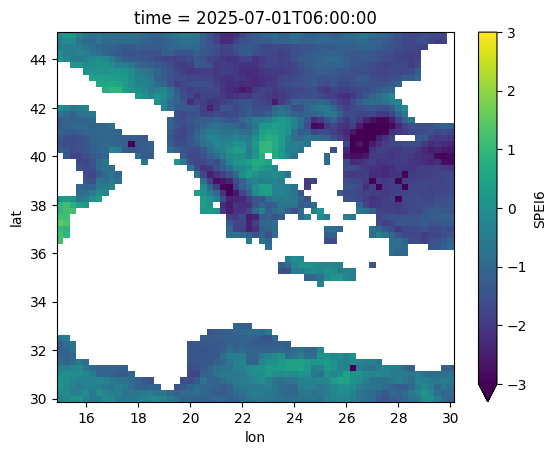

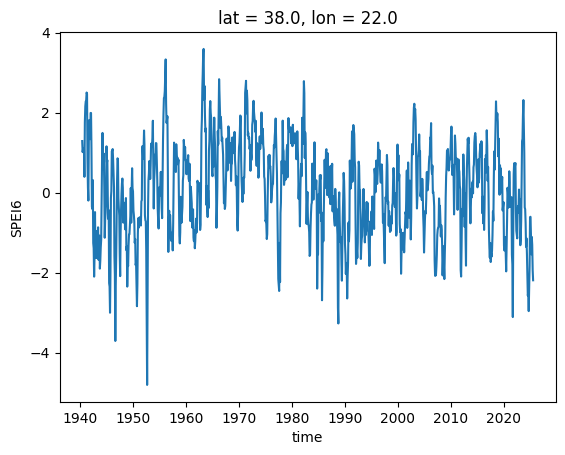

In [7]:
print(drought_hist.isel(time=-1))

drought_hist['SPEI6'].isel(time=-1).plot(vmax=3, vmin=-3)

plt.figure()
drought_hist['SPEI6'].sel(lon=22, lat=38, method="nearest").plot()

In [10]:
print((drought_hist > 10000))

<xarray.Dataset> Size: 4MB
Dimensions:  (time: 1022, lat: 61, lon: 61)
Coordinates:
  * time     (time) datetime64[ns] 8kB 1940-06-01T06:00:00 ... 2025-07-01T06:...
  * lat      (lat) float64 488B 45.0 44.75 44.5 44.25 ... 30.75 30.5 30.25 30.0
  * lon      (lon) float64 488B 15.0 15.25 15.5 15.75 ... 29.25 29.5 29.75 30.0
Data variables:
    SPEI6    (time, lat, lon) bool 4MB dask.array<chunksize=(1, 61, 61), meta=np.ndarray>


In [ ]:
def is_clean(dataset):
    return all((v != -9999).all() for v in dataset.data_vars.values())

def check_jumps(dataset):
    return all(((v <= -8) | (v>= 8)).all() for v in dataset.data_vars.values())

print(f"The dataset is clean of -9999: {is_clean(drought_hist)}")
print(f"The dataset has pixels with -8/+8 jumps: {check_jumps(drought_hist)}")

The dataset is clean of -9999: True


In [ ]:
# Condition: values >= 8 or <= -8
condition = (drought_hist['SPEI6'] >= 8) | (drought_hist['SPEI6'] <= -8)

# Now find where ALL time steps satisfy the condition
jumps = condition.all(dim="time")
#print((jumps ==1).any().values)
if (jumps == 1).any().values:
    (jumps['SPEI6']).plot()

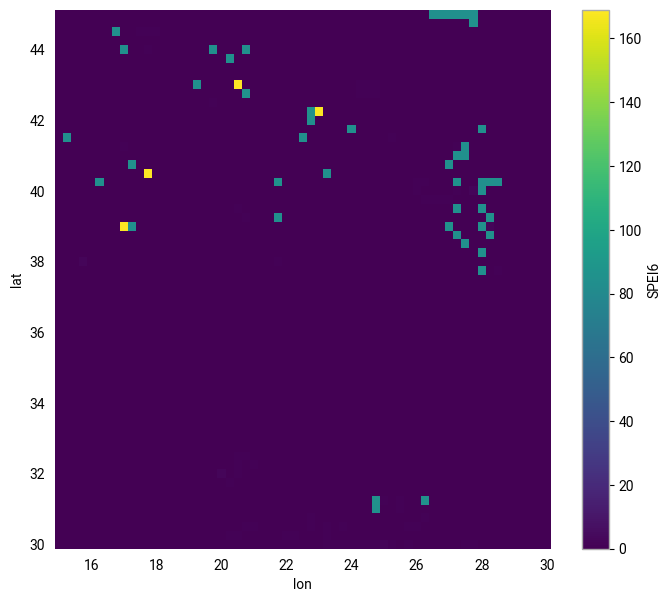

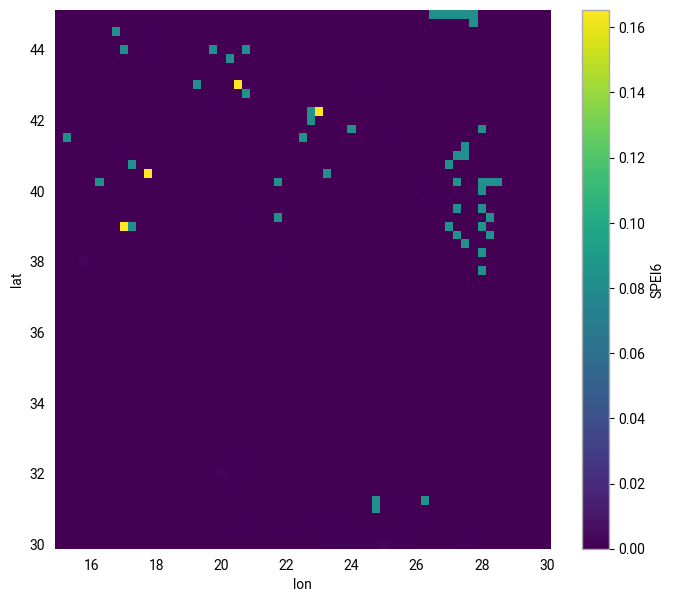

In [111]:
condition = (drought_hist['SPEI6'] >= 8) | (drought_hist['SPEI6'] <= -8)

# Count along the time dimension
count_extreme = condition.sum(dim="time")
count_extreme.plot()

# Fraction of high values
count_mean = condition.mean(dim="time")
plt.figure(); count_mean.plot()